### Imports

In [ ]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect("sakila.duckdb")

### Movies longer than 180 minutes

In [ ]:
query = """
SELECT title, length
FROM film
WHERE length > 180
"""
df_long_movies = con.execute(query).df()
df_long_movies

,title,length
0,ANALYZE HOOSIERS,181
1,BAKED CLEOPATRA,182
2,CATCH AMISTAD,183
3,CHICAGO NORTH,185
4,CONSPIRACY SPIRIT,184
5,CONTROL ANTHEM,185
6,CRYSTAL BREAKING,184
7,DARN FORRESTER,185
8,FRONTIER CABIN,183
9,GANGS PRIDE,185


### Movies that involves the word love

In [ ]:
query = """
SELECT title, rating, length, description
FROM film
WHERE lower(title) LIKE '%love%'
"""
df_love = con.execute(query).df()
df_love

,title,rating,length,description
0,GRAFFITI LOVE,PG,117,A Unbelieveable Epistle of a Sumo Wrestler And...
1,IDAHO LOVE,PG-13,172,A Fast-Paced Drama of a Student And a Crocodil...
2,IDENTITY LOVER,PG-13,119,A Boring Tale of a Composer And a Mad Cow who ...
3,INDIAN LOVE,NC-17,135,A Insightful Saga of a Mad Scientist And a Mad...
4,LAWRENCE LOVE,NC-17,175,A Fanciful Yarn of a Database Administrator An...
5,LOVE SUICIDES,R,181,A Brilliant Panorama of a Hunter And a Explore...
6,LOVELY JINGLE,PG,65,A Fanciful Yarn of a Crocodile And a Forensic ...
7,LOVER TRUMAN,G,75,A Emotional Yarn of a Robot And a Boy who must...
8,LOVERBOY ATTACKS,PG-13,162,A Boring Story of a Car And a Butler who must ...
9,STRANGELOVE DESIRE,NC-17,103,A Awe-Inspiring Panorama of a Lumberjack And a...


### Statistic of the movies length

In [ ]:
query = """
SELECT 
    MIN(length) AS shortest,
    AVG(length) AS average,
    MEDIAN(length) AS median,
    MAX(length) AS longest
FROM film
"""
df_stats = con.execute(query).df()
df_stats

,shortest,average,median,longest
0,46,115.272,114.0,185


### Top 10 expensive movies per day

In [ ]:
query = """
SELECT 
    title,
    rental_rate / rental_duration AS cost_per_day
FROM film
ORDER BY cost_per_day DESC
LIMIT 10
"""
df_expensive = con.execute(query).df()
df_expensive

,title,cost_per_day
0,ACE GOLDFINGER,1.663333
1,AMERICAN CIRCUS,1.663333
2,AUTUMN CROW,1.663333
3,BACKLASH UNDEFEATED,1.663333
4,BEAST HUNCHBACK,1.663333
5,BEHAVIOR RUNAWAY,1.663333
6,BILKO ANONYMOUS,1.663333
7,CARIBBEAN LIBERTY,1.663333
8,CASPER DRAGONFLY,1.663333
9,CASUALTIES ENCINO,1.663333


### Actors that has played in most movies

In [ ]:
query = """
SELECT 
    a.first_name || ' ' || a.last_name AS actor_name,
    COUNT(fa.film_id) AS number_of_movies
FROM actor a
JOIN film_actor fa ON a.actor_id = fa.actor_id
GROUP BY actor_name
ORDER BY number_of_movies DESC
LIMIT 10
"""
df_actors = con.execute(query).df()
df_actors

,actor_name,number_of_movies
0,SUSAN DAVIS,54
1,GINA DEGENERES,42
2,WALTER TORN,41
3,MARY KEITEL,40
4,MATTHEW CARREY,39
5,SANDRA KILMER,37
6,SCARLETT DAMON,36
7,GROUCHO DUNST,35
8,ANGELA WITHERSPOON,35
9,VIVIEN BASINGER,35


### Which category has the most movies

In [ ]:
query = """
SELECT 
    c.name AS category,
    COUNT(fc.film_id) AS number_of_movies
FROM category c
JOIN film_category fc ON c.category_id = fc.category_id
GROUP BY c.name
ORDER BY number_of_movies DESC
LIMIT 10
"""

df_categories = con.execute(query).df()
df_categories

,category,number_of_movies
0,Sports,74
1,Foreign,73
2,Family,69
3,Documentary,68
4,Animation,66
5,Action,64
6,New,63
7,Drama,62
8,Sci-Fi,61
9,Games,61


### Most rented out movie

In [ ]:
query = """
SELECT 
    f.title,
    COUNT(r.rental_id) AS rentals
FROM film f
JOIN inventory i ON f.film_id = i.film_id
JOIN rental r ON i.inventory_id = r.inventory_id
GROUP BY f.title
ORDER BY rentals DESC
LIMIT 10
"""

df_rentals = con.execute(query).df()
df_rentals

,title,rentals
0,BUCKET BROTHERHOOD,34
1,ROCKETEER MOTHER,33
2,JUGGLER HARDLY,32
3,RIDGEMONT SUBMARINE,32
4,FORWARD TEMPLE,32
5,SCALAWAG DUCK,32
6,GRIT CLOCKWORK,32
7,GOODFELLAS SALUTE,31
8,ZORRO ARK,31
9,APACHE DIVINE,31


### Top 5 customers

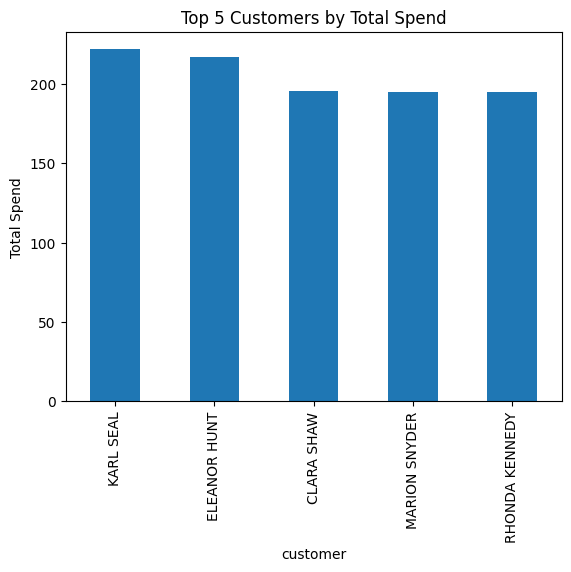

In [ ]:
query = """
SELECT 
    c.first_name || ' ' || c.last_name AS customer,
    SUM(p.amount) AS total_spend
FROM customer c
JOIN payment p ON c.customer_id = p.customer_id
GROUP BY customer
ORDER BY total_spend DESC
LIMIT 5
"""
df_top_customers = con.execute(query).df()

df_top_customers.plot(
    kind="bar",
    x="customer",
    y="total_spend",
    legend=False,
    title="Top 5 Customers by Total Spend"
)
plt.ylabel("Total Spend")
plt.show()

### Income per movie category

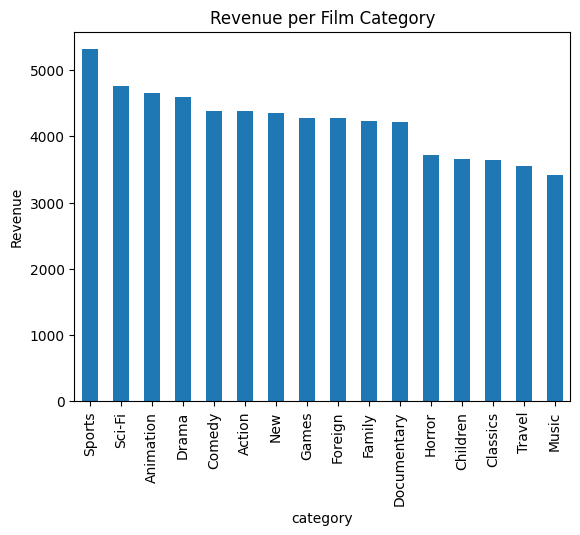

In [ ]:
query = """
SELECT 
    c.name AS category,
    SUM(p.amount) AS revenue
FROM category c
JOIN film_category fc ON c.category_id = fc.category_id
JOIN inventory i ON fc.film_id = i.film_id
JOIN rental r ON i.inventory_id = r.inventory_id
JOIN payment p ON r.rental_id = p.rental_id
GROUP BY category
ORDER BY revenue DESC
"""
df_revenue = con.execute(query).df()

df_revenue.plot(
    kind="bar",
    x="category",
    y="revenue",
    legend=False,
    title="Revenue per Film Category"
)
plt.ylabel("Revenue")
plt.show()